In [1]:
# Step 1: Import required libraries

import numpy as np
import pandas as pd
from pathlib import Path

# Step 2: Define dataset location

DATA_DIR = Path("../data/raw/CMAPSSData")

# Step 3: Define column names

columns = (
    ["unit", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Step 4: Load all four datasets

datasets = {}

for fd in ["FD001", "FD002", "FD003", "FD004"]:

    train = pd.read_csv(
        DATA_DIR / f"train_{fd}.txt",
        sep=r"\s+",
        header=None
    )

    test = pd.read_csv(
        DATA_DIR / f"test_{fd}.txt",
        sep=r"\s+",
        header=None
    )

    rul = pd.read_csv(
        DATA_DIR / f"RUL_{fd}.txt",
        sep=r"\s+",
        header=None
    )

    # Remove extra empty columns, if present
    train = train.iloc[:, :26]
    test = test.iloc[:, :26]

    train.columns = columns
    test.columns = columns

    datasets[fd] = {
        "train": train,
        "test": test,
        "rul": rul
    }

print("All four datasets loaded successfully!")

All four datasets loaded successfully!


In [2]:
# Step 2: Compare dataset sizes

summary = []

for fd, data in datasets.items():

    train = data["train"]
    test = data["test"]
    rul = data["rul"]

    summary.append({
        "Dataset": fd,
        "Train Engines": train["unit"].nunique(),
        "Train Rows": len(train),
        "Test Engines": test["unit"].nunique(),
        "Test Rows": len(test),
        "RUL Labels": len(rul)
    })

summary_df = pd.DataFrame(summary)

summary_df

,Dataset,Train Engines,Train Rows,Test Engines,Test Rows,RUL Labels
0,FD001,100,20631,100,13096,100
1,FD002,260,53759,259,33991,259
2,FD003,100,24720,100,16596,100
3,FD004,249,61249,248,41214,248


In [3]:
# Step 3: Analyze operating conditions

for fd, data in datasets.items():

    train = data["train"]

    unique_conditions = train[
        ["setting_1", "setting_2", "setting_3"]
    ].drop_duplicates()

    print(f"\n{fd}")
    print("Unique operating-setting combinations:",
          len(unique_conditions))


FD001
Unique operating-setting combinations: 1423

FD002
Unique operating-setting combinations: 9824

FD003
Unique operating-setting combinations: 1479

FD004
Unique operating-setting combinations: 10232


In [4]:
# Step 4: Inspect operating settings

for fd, data in datasets.items():

    print(f"\n{'='*40}")
    print(fd)
    print(f"{'='*40}")

    print(
        data["train"][
            ["setting_1", "setting_2", "setting_3"]
        ].describe().round(3)
    )


FD001
       setting_1  setting_2  setting_3
count  20631.000  20631.000    20631.0
mean      -0.000      0.000      100.0
std        0.002      0.000        0.0
min       -0.009     -0.001      100.0
25%       -0.002     -0.000      100.0
50%        0.000      0.000      100.0
75%        0.002      0.000      100.0
max        0.009      0.001      100.0

FD002
       setting_1  setting_2  setting_3
count  53759.000  53759.000  53759.000
mean      23.998      0.572     94.046
std       14.747      0.310     14.238
min        0.000      0.000     60.000
25%       10.005      0.251    100.000
50%       25.001      0.700    100.000
75%       41.998      0.840    100.000
max       42.008      0.842    100.000

FD003
       setting_1  setting_2  setting_3
count  24720.000  24720.000    24720.0
mean      -0.000      0.000      100.0
std        0.002      0.000        0.0
min       -0.009     -0.001      100.0
25%       -0.002     -0.000      100.0
50%       -0.000     -0.000      100.0
75% 

In [5]:
# Step 5: Compare operating settings across datasets

for fd, data in datasets.items():

    train = data["train"]

    print(f"\n{fd}")

    for setting in ["setting_1", "setting_2", "setting_3"]:

        print(
            f"{setting}: "
            f"min={train[setting].min():.3f}, "
            f"max={train[setting].max():.3f}, "
            f"std={train[setting].std():.3f}, "
            f"unique={train[setting].nunique()}"
        )


FD001
setting_1: min=-0.009, max=0.009, std=0.002, unique=158
setting_2: min=-0.001, max=0.001, std=0.000, unique=13
setting_3: min=100.000, max=100.000, std=0.000, unique=1

FD002
setting_1: min=0.000, max=42.008, std=14.747, unique=536
setting_2: min=0.000, max=0.842, std=0.310, unique=105
setting_3: min=60.000, max=100.000, std=14.238, unique=2

FD003
setting_1: min=-0.009, max=0.009, std=0.002, unique=160
setting_2: min=-0.001, max=0.001, std=0.000, unique=14
setting_3: min=100.000, max=100.000, std=0.000, unique=1

FD004
setting_1: min=0.000, max=42.008, std=14.781, unique=536
setting_2: min=0.000, max=0.842, std=0.311, unique=105
setting_3: min=60.000, max=100.000, std=14.252, unique=2


In [6]:
# Step 6: Dataset characteristics

characteristics = pd.DataFrame({
    "Dataset": ["FD001", "FD002", "FD003", "FD004"],
    "Operating Conditions": [1, 6, 1, 6],
    "Fault Modes": [1, 1, 2, 2]
})

characteristics

,Dataset,Operating Conditions,Fault Modes
0,FD001,1,1
1,FD002,6,1
2,FD003,1,2
3,FD004,6,2


In [7]:
# Step 7: Identify constant sensors in each dataset

for fd, data in datasets.items():

    train = data["train"]

    sensor_columns = [
        col for col in train.columns
        if col.startswith("sensor_")
    ]

    constant_sensors = [
        col for col in sensor_columns
        if train[col].nunique() == 1
    ]

    print(f"\n{fd}")
    print("Number of constant sensors:", len(constant_sensors))
    print("Constant sensors:", constant_sensors)
    print("Variable sensors:", len(sensor_columns) - len(constant_sensors))


FD001
Number of constant sensors: 6
Constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Variable sensors: 15

FD002
Number of constant sensors: 0
Constant sensors: []
Variable sensors: 21

FD003
Number of constant sensors: 5
Constant sensors: ['sensor_1', 'sensor_5', 'sensor_16', 'sensor_18', 'sensor_19']
Variable sensors: 16

FD004
Number of constant sensors: 0
Constant sensors: []
Variable sensors: 21


In [8]:
# Step 8: Analyze engine lifetime distributions

for fd, data in datasets.items():

    train = data["train"]

    engine_lifetimes = train.groupby("unit")["cycle"].max()

    print(f"\n{fd}")
    print(engine_lifetimes.describe().round(2))


FD001
count    100.00
mean     206.31
std       46.34
min      128.00
25%      177.00
50%      199.00
75%      229.25
max      362.00
Name: cycle, dtype: float64

FD002
count    260.00
mean     206.77
std       46.78
min      128.00
25%      174.00
50%      199.00
75%      230.25
max      378.00
Name: cycle, dtype: float64

FD003
count    100.00
mean     247.20
std       86.48
min      145.00
25%      189.75
50%      220.50
75%      279.75
max      525.00
Name: cycle, dtype: float64

FD004
count    249.00
mean     245.98
std       73.11
min      128.00
25%      190.00
50%      234.00
75%      290.00
max      543.00
Name: cycle, dtype: float64


In [9]:
# Step 9: Compare engine lifetimes across datasets

lifetime_summary = []

for fd, data in datasets.items():

    lifetimes = data["train"].groupby("unit")["cycle"].max()

    lifetime_summary.append({
        "Dataset": fd,
        "Engines": lifetimes.count(),
        "Mean Lifetime": round(lifetimes.mean(), 2),
        "Std": round(lifetimes.std(), 2),
        "Minimum": lifetimes.min(),
        "Median": lifetimes.median(),
        "Maximum": lifetimes.max()
    })

lifetime_df = pd.DataFrame(lifetime_summary)

lifetime_df

,Dataset,Engines,Mean Lifetime,Std,Minimum,Median,Maximum
0,FD001,100,206.31,46.34,128,199.0,362
1,FD002,260,206.77,46.78,128,199.0,378
2,FD003,100,247.20,86.48,145,220.5,525
3,FD004,249,245.98,73.11,128,234.0,543


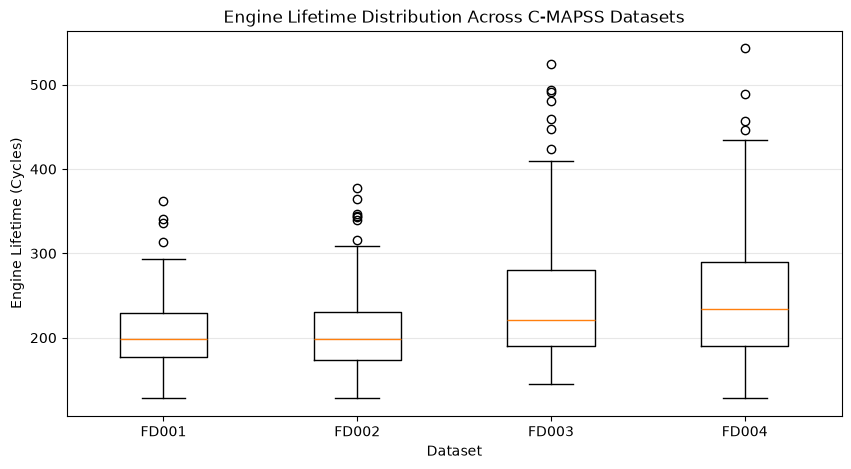

In [10]:
# Step 10: Visualize engine lifetime distributions

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

lifetime_data = []

for fd, data in datasets.items():

    lifetimes = data["train"].groupby("unit")["cycle"].max()
    lifetime_data.append(lifetimes.values)

plt.boxplot(
    lifetime_data,
    tick_labels=["FD001", "FD002", "FD003", "FD004"]
)

plt.title("Engine Lifetime Distribution Across C-MAPSS Datasets")
plt.xlabel("Dataset")
plt.ylabel("Engine Lifetime (Cycles)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [11]:
# Step 11: Data quality check

for fd, data in datasets.items():

    train = data["train"]
    test = data["test"]

    print(f"\n{'='*35}")
    print(fd)
    print(f"{'='*35}")

    print("Training missing values:", train.isnull().sum().sum())
    print("Testing missing values:", test.isnull().sum().sum())

    print("Training duplicate rows:", train.duplicated().sum())
    print("Testing duplicate rows:", test.duplicated().sum())


FD001
Training missing values: 0
Testing missing values: 0
Training duplicate rows: 0
Testing duplicate rows: 0

FD002
Training missing values: 0
Testing missing values: 0
Training duplicate rows: 0
Testing duplicate rows: 0

FD003
Training missing values: 0
Testing missing values: 0
Training duplicate rows: 0
Testing duplicate rows: 0

FD004
Training missing values: 0
Testing missing values: 0
Training duplicate rows: 0
Testing duplicate rows: 0


In [12]:
# Step 12: Compare sensor standard deviations

sensor_variability = {}

for fd, data in datasets.items():

    train = data["train"]

    sensor_columns = [
        col for col in train.columns
        if col.startswith("sensor_")
    ]

    sensor_std = train[sensor_columns].std().sort_values(
        ascending=False
    )

    sensor_variability[fd] = sensor_std

    print(f"\n{fd} - Top 5 variable sensors")
    print(sensor_std.head(5).round(3))


FD001 - Top 5 variable sensors
sensor_9     22.083
sensor_14    19.076
sensor_4      9.001
sensor_3      6.131
sensor_17     1.549
dtype: float64

FD002 - Top 5 variable sensors
sensor_9     335.812
sensor_7     146.005
sensor_18    145.328
sensor_8     145.210
sensor_12    137.660
dtype: float64

FD003 - Top 5 variable sensors
sensor_9     19.980
sensor_14    16.504
sensor_4      9.773
sensor_3      6.810
sensor_7      3.437
dtype: float64

FD004 - Top 5 variable sensors
sensor_9     336.928
sensor_7     146.880
sensor_18    145.472
sensor_8     145.348
sensor_12    138.479
dtype: float64


In [13]:
# Step 13: Compare top variable sensors

top_sensors = {}

for fd, sensor_std in sensor_variability.items():

    top_sensors[fd] = [
        f"{sensor}: {value:.2f}"
        for sensor, value in sensor_std.head(5).items()
    ]

top_sensor_df = pd.DataFrame(top_sensors, index=[
    "Rank 1", "Rank 2", "Rank 3", "Rank 4", "Rank 5"
])

top_sensor_df

,FD001,FD002,FD003,FD004
Rank 1,sensor_9: 22.08,sensor_9: 335.81,sensor_9: 19.98,sensor_9: 336.93
Rank 2,sensor_14: 19.08,sensor_7: 146.01,sensor_14: 16.50,sensor_7: 146.88
Rank 3,sensor_4: 9.00,sensor_18: 145.33,sensor_4: 9.77,sensor_18: 145.47
Rank 4,sensor_3: 6.13,sensor_8: 145.21,sensor_3: 6.81,sensor_8: 145.35
Rank 5,sensor_17: 1.55,sensor_12: 137.66,sensor_7: 3.44,sensor_12: 138.48


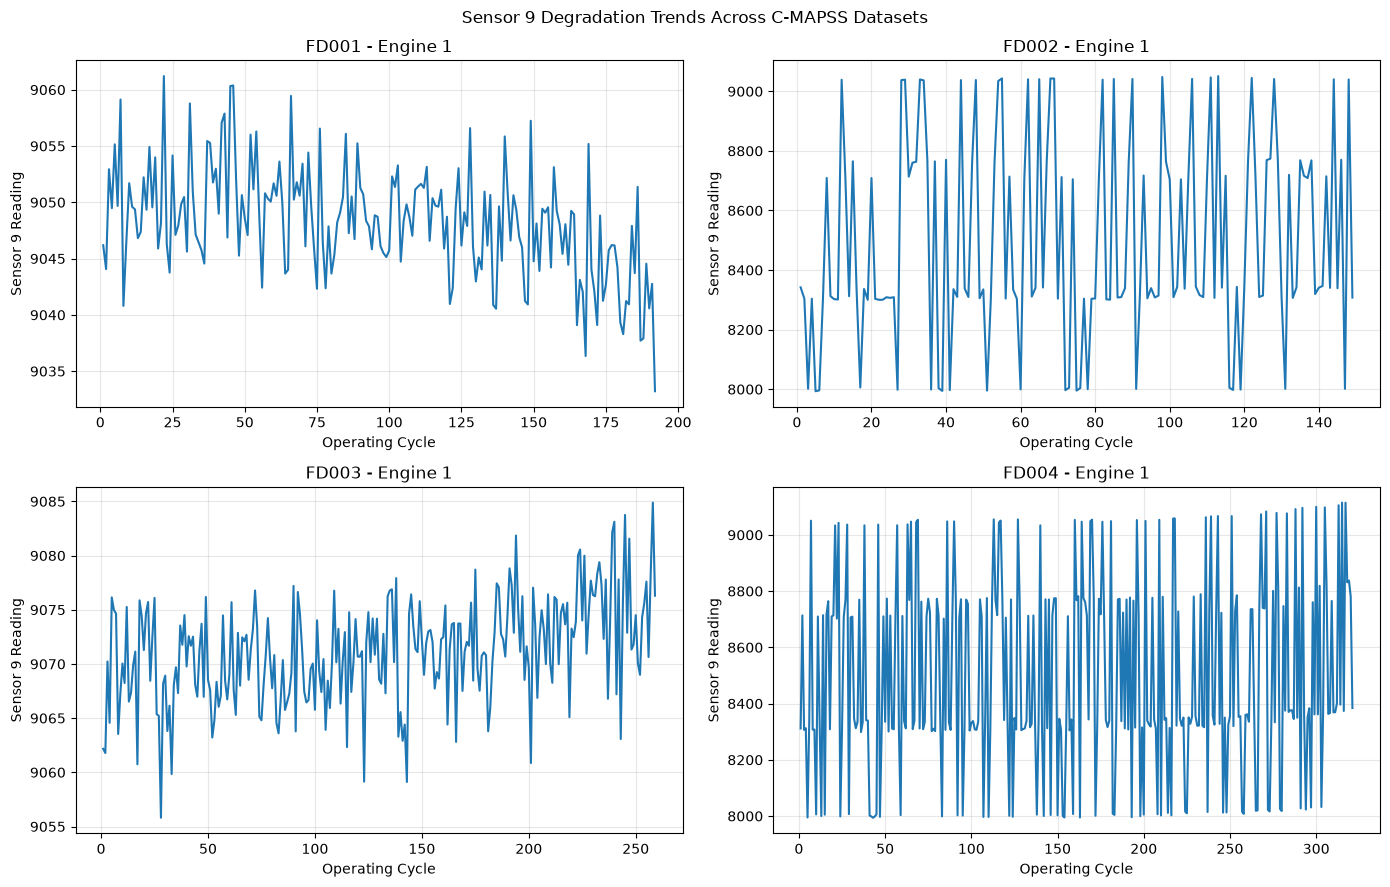

In [14]:
# Step 14: Compare sensor_9 trends across datasets

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (fd, data) in zip(axes.flatten(), datasets.items()):

    engine_data = data["train"][
        data["train"]["unit"] == 1
    ]

    ax.plot(
        engine_data["cycle"],
        engine_data["sensor_9"]
    )

    ax.set_title(f"{fd} - Engine 1")
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Sensor 9 Reading")
    ax.grid(alpha=0.3)

plt.suptitle("Sensor 9 Degradation Trends Across C-MAPSS Datasets")
plt.tight_layout()
plt.show()

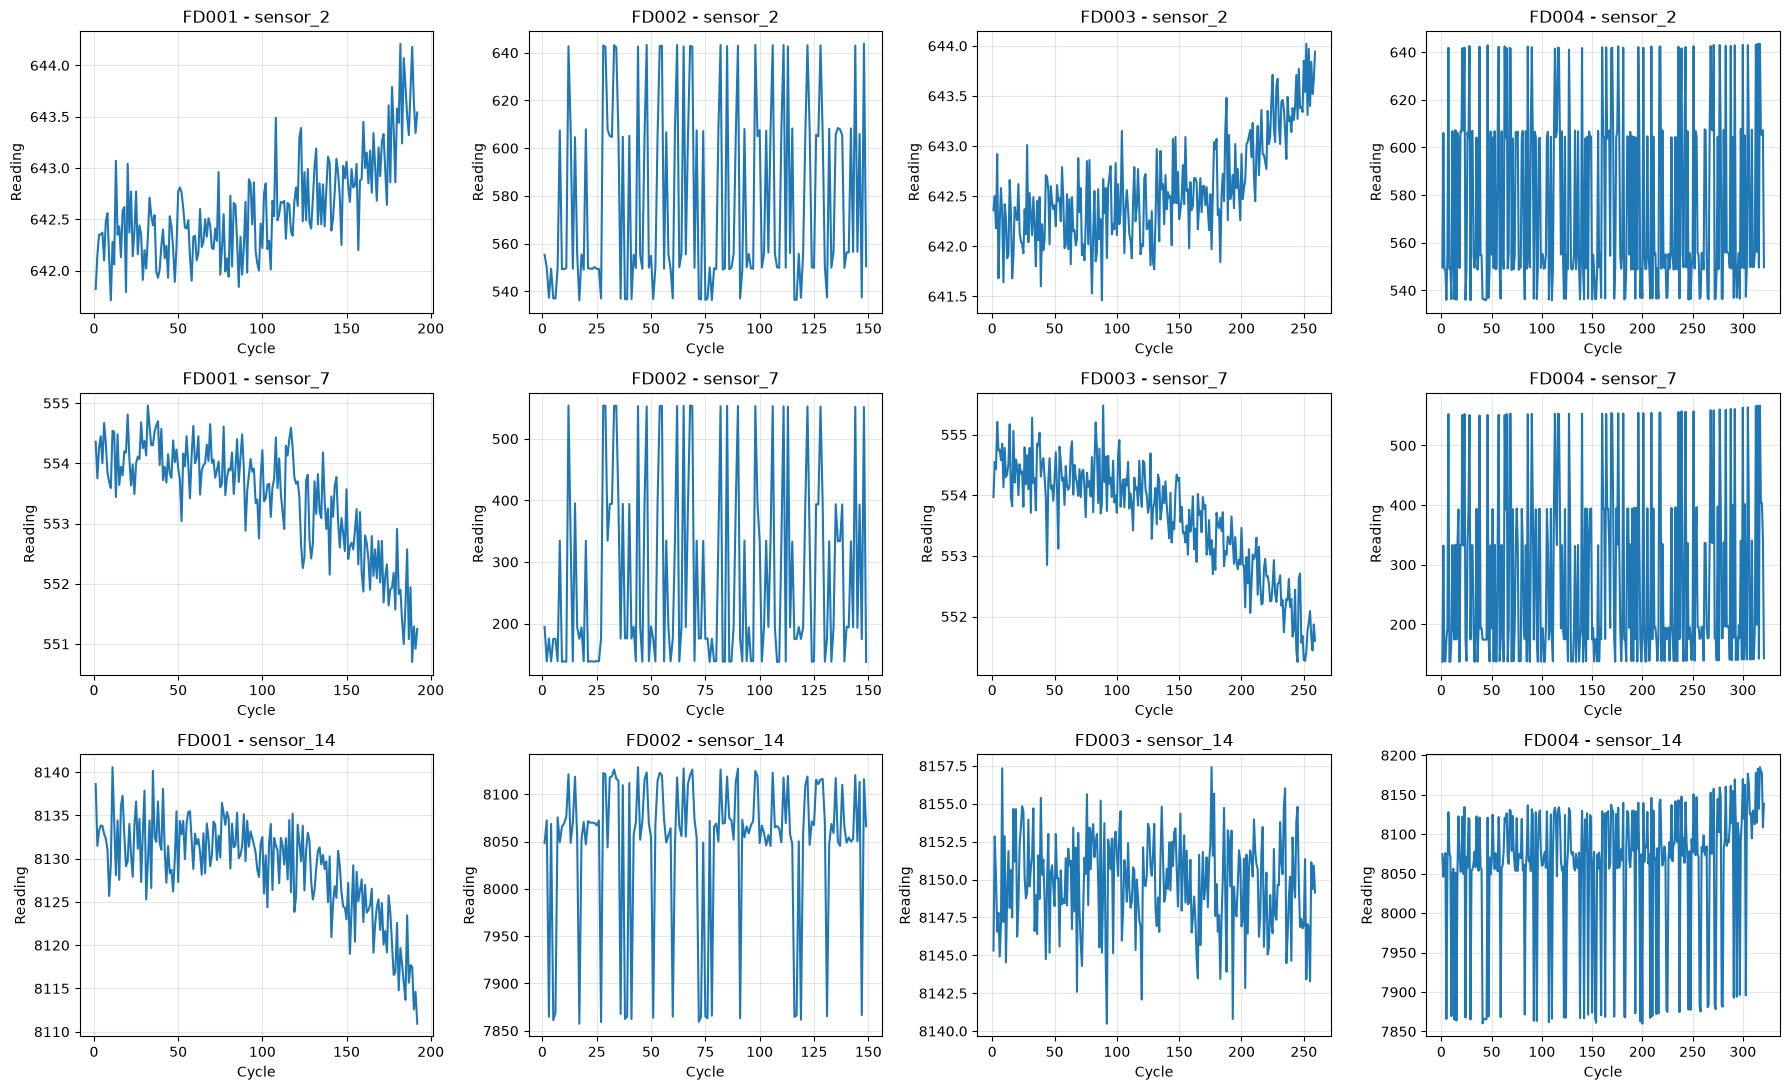

In [15]:
# Step 15: Compare multiple sensor trends

selected_sensors = ["sensor_2", "sensor_7", "sensor_14"]

fig, axes = plt.subplots(3, 4, figsize=(18, 11))

for col, (fd, data) in enumerate(datasets.items()):

    engine_data = data["train"][
        data["train"]["unit"] == 1
    ]

    for row, sensor in enumerate(selected_sensors):

        axes[row, col].plot(
            engine_data["cycle"],
            engine_data[sensor]
        )

        axes[row, col].set_title(f"{fd} - {sensor}")
        axes[row, col].set_xlabel("Cycle")
        axes[row, col].set_ylabel("Reading")
        axes[row, col].grid(alpha=0.3)

plt.tight_layout()
plt.show()


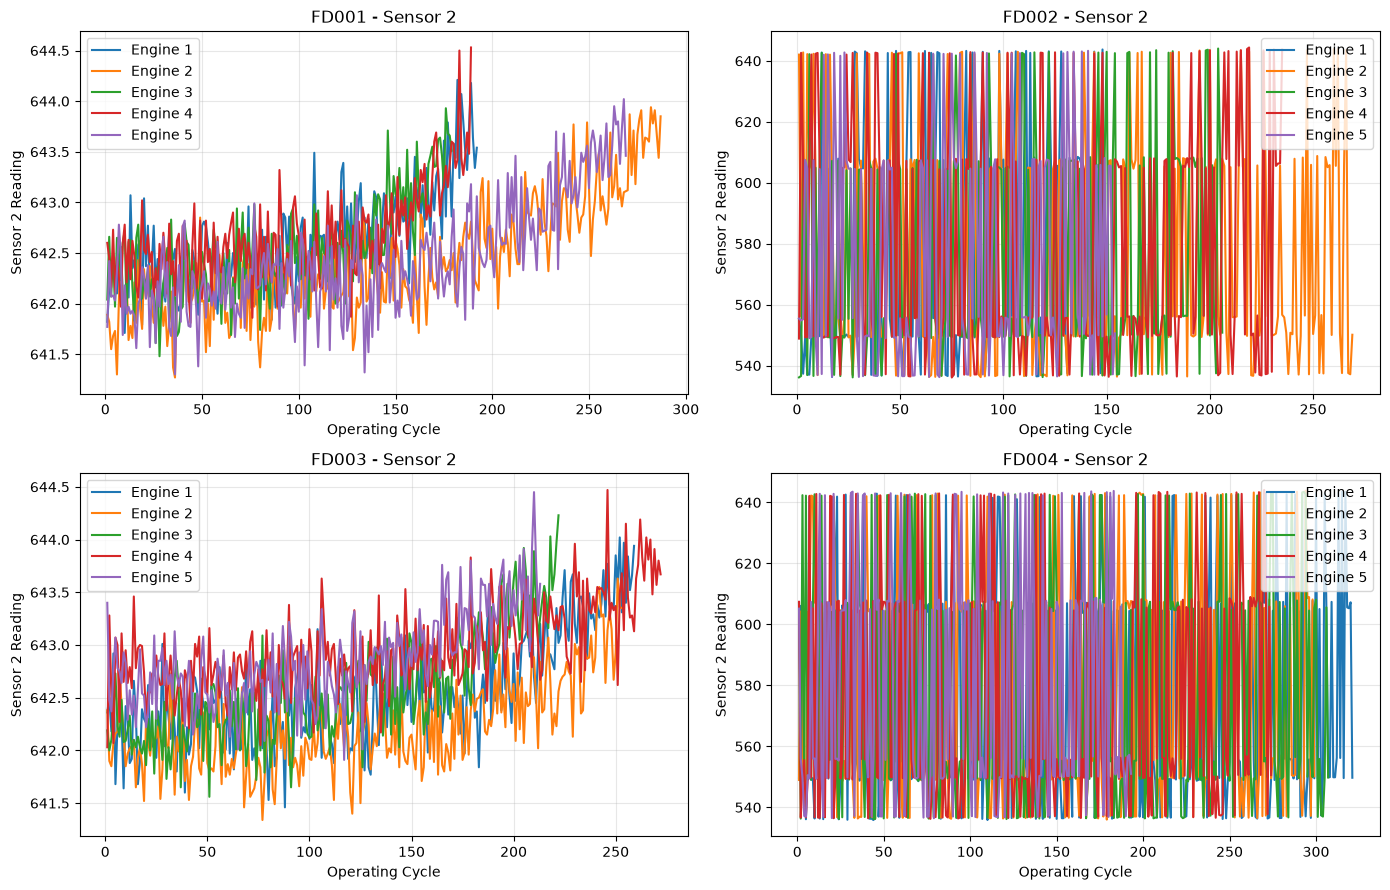

In [16]:
# Step 16: Compare sensor behavior across engines

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (fd, data) in zip(axes.flatten(), datasets.items()):

    train = data["train"]

    for engine_id in [1, 2, 3, 4, 5]:

        engine_data = train[
            train["unit"] == engine_id
        ]

        ax.plot(
            engine_data["cycle"],
            engine_data["sensor_2"],
            label=f"Engine {engine_id}"
        )

    ax.set_title(f"{fd} - Sensor 2")
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Sensor 2 Reading")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

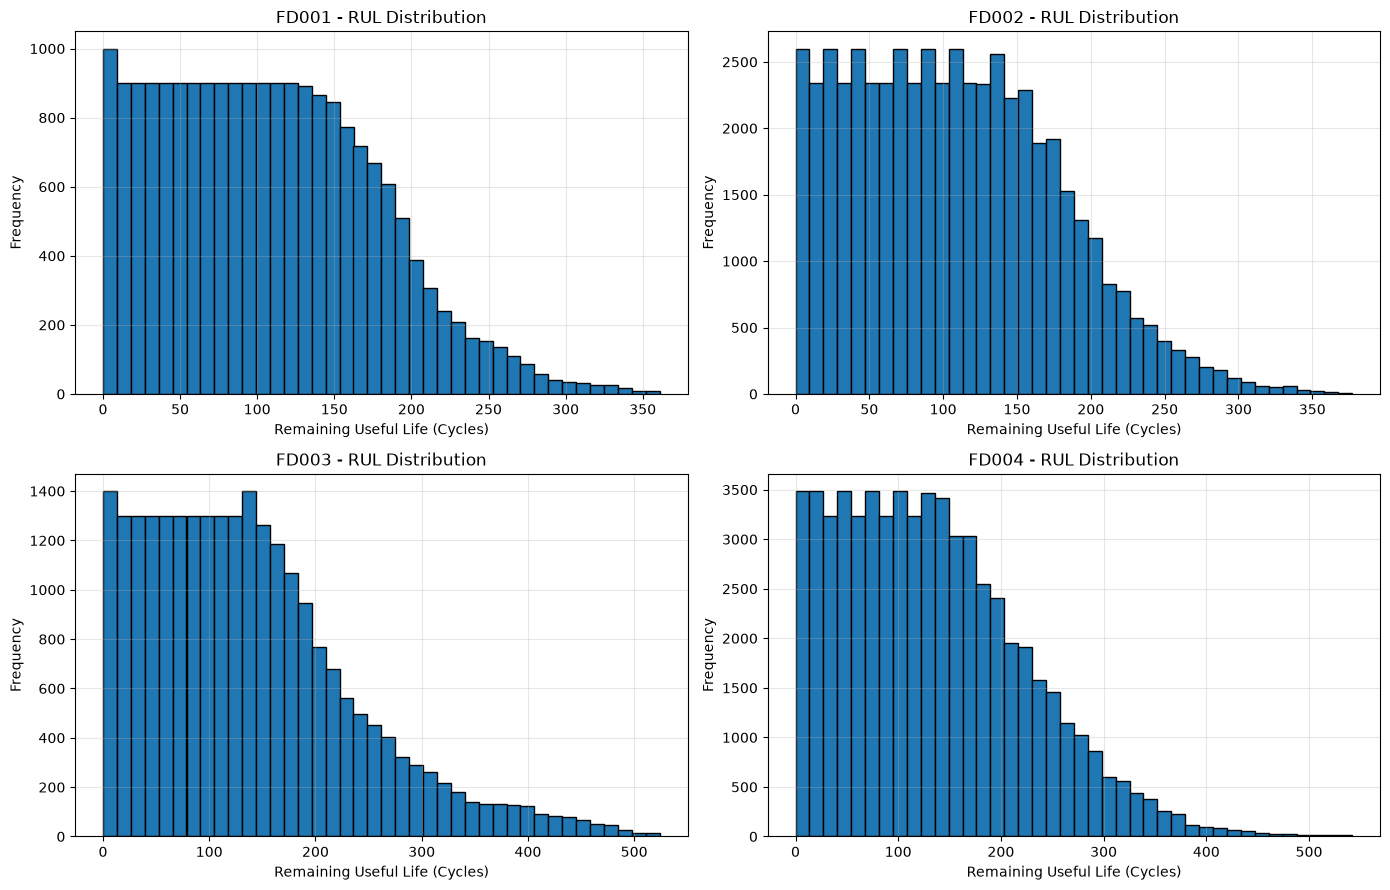

In [17]:
# Step 17: Compare RUL distributions

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (fd, data) in zip(axes.flatten(), datasets.items()):

    train = data["train"].copy()

    # Calculate RUL for every training observation
    max_cycles = train.groupby("unit")["cycle"].transform("max")
    train["RUL"] = max_cycles - train["cycle"]

    ax.hist(train["RUL"], bins=40, edgecolor="black")

    ax.set_title(f"{fd} - RUL Distribution")
    ax.set_xlabel("Remaining Useful Life (Cycles)")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
# Step 18: Sensor correlation with RUL

correlation_results = {}

for fd, data in datasets.items():

    train = data["train"].copy()

    max_cycles = train.groupby("unit")["cycle"].transform("max")
    train["RUL"] = max_cycles - train["cycle"]

    sensor_columns = [
        col for col in train.columns
        if col.startswith("sensor_")
    ]

    correlations = (
        train[sensor_columns + ["RUL"]]
        .corr()["RUL"]
        .drop("RUL")
        .sort_values(key=abs, ascending=False)
    )

    correlation_results[fd] = correlations

    print(f"\n{fd} - Top 5 sensors correlated with RUL")
    print(correlations.head(5).round(3))


FD001 - Top 5 sensors correlated with RUL
sensor_11   -0.696
sensor_4    -0.679
sensor_12    0.672
sensor_7     0.657
sensor_15   -0.643
Name: RUL, dtype: float64

FD002 - Top 5 sensors correlated with RUL
sensor_16   -0.071
sensor_11   -0.047
sensor_14   -0.042
sensor_4    -0.041
sensor_15   -0.038
Name: RUL, dtype: float64

FD003 - Top 5 sensors correlated with RUL
sensor_11   -0.689
sensor_4    -0.657
sensor_13   -0.656
sensor_8    -0.655
sensor_17   -0.649
Name: RUL, dtype: float64

FD004 - Top 5 sensors correlated with RUL
sensor_14   -0.078
sensor_11   -0.057
sensor_16   -0.054
sensor_4    -0.046
sensor_17   -0.033
Name: RUL, dtype: float64


In [19]:
print("FD004 - Top 5 sensors correlated with RUL")
print(correlation_results["FD004"].head(5).round(3))

FD004 - Top 5 sensors correlated with RUL
sensor_14   -0.078
sensor_11   -0.057
sensor_16   -0.054
sensor_4    -0.046
sensor_17   -0.033
Name: RUL, dtype: float64
